Name: Ketki Gaikwad

Roll no.:23102A0060

CMPN-A



# Laboratory Assignment 8: High-Performance Big Data Analytics Using R

**Dataset:** NYC TLC Yellow Taxi Trip Records (Jan to Mar 2023) with the Taxi Zone Lookup Table

**Flow:** Problem Statement → Dataset → Data Preparation → Implementation → Analysis → Benchmarking → Visualizations → Observations → Critical Analysis → Conclusion

**Runtime:** Works on the free Colab CPU runtime (about 2 vCPUs, about 12 GB RAM). Run cells top to bottom. The first run takes about 10 to 15 minutes because of package installation and the data download.

## 1. Problem Statement

The NYC Taxi and Limousine Commission generates millions of trip records. Conventional processing of data at this scale is slow and memory hungry. This notebook builds an analytics pipeline in R that:

- uses **data.table** for filtering, joining, grouping and aggregation,
- compares **apply / lapply / purrr::map** with **vectorized** and **data.table** code,
- runs a partitioned workload **sequentially and in parallel** (foreach + doParallel) and calculates speedup,
- benchmarks everything with **microbenchmark** and **system.time**,
- finds travel, demand, revenue, fare, distance and payment patterns and visualizes them with **ggplot2**.

## 2. Setup: Install and Load Packages

In [1]:
install.packages(c('data.table', 'ggplot2', 'foreach', 'doParallel', 'microbenchmark', 'purrr', 'lubridate', 'arrow'), quiet = TRUE)

also installing the dependencies ‘iterators’, ‘assertthat’




In [2]:
library(data.table)
library(ggplot2)
library(foreach)
library(doParallel)
library(microbenchmark)
library(purrr)
library(lubridate)
library(arrow)

options(scipen = 999, datatable.print.nrows = 15)
cat('Cores detected:', parallel::detectCores(), '\n')


Attaching package: ‘data.table’


The following object is masked from ‘package:base’:

    %notin%


Loading required package: iterators

Loading required package: parallel


Attaching package: ‘purrr’


The following objects are masked from ‘package:foreach’:

    accumulate, when


The following object is masked from ‘package:data.table’:

    transpose



Attaching package: ‘lubridate’


The following objects are masked from ‘package:data.table’:

    hour, isoweek, isoyear, mday, minute, month, quarter, second, wday,
    week, yday, year


The following objects are masked from ‘package:base’:

    date, intersect, setdiff, union



Attaching package: ‘arrow’


The following object is masked from ‘package:lubridate’:

    duration


The following object is masked from ‘package:utils’:

    timestamp




Cores detected: 2 


## 3. Task 1: Data Acquisition and Preparation

We download three months of Yellow Taxi data (Parquet files from the official TLC CloudFront bucket linked on the TLC trip record page) and the Taxi Zone Lookup Table.

In [3]:
BASE_URL <- 'https://d37ci6vzurychx.cloudfront.net/trip-data/'
ZONE_URL <- 'https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv'
months   <- c('2023-01', '2023-02', '2023-03')
files    <- paste0('yellow_tripdata_', months, '.parquet')

data_dir <- 'data'
dir.create(data_dir, showWarnings = FALSE)

# Download only if not already present
walk(files, function(f) {
  dest <- file.path(data_dir, f)
  if (!file.exists(dest)) download.file(paste0(BASE_URL, f), dest, mode = 'wb')
})
zone_path <- file.path(data_dir, 'taxi_zone_lookup.csv')
if (!file.exists(zone_path)) download.file(ZONE_URL, zone_path, mode = 'wb')

# Read all months and stack them with data.table
t_load <- system.time({
  trips_raw <- rbindlist(
    lapply(files, function(f) as.data.table(read_parquet(file.path(data_dir, f)))),
    use.names = TRUE, fill = TRUE)
})
cat('Rows loaded:', format(nrow(trips_raw), big.mark = ','), '| load time (s):', t_load['elapsed'], '\n')

Rows loaded: 9,384,487 | load time (s): 11.815 


### 3.1 Inspect structure, types and summary statistics

In [4]:
dim(trips_raw)
str(trips_raw)
summary(trips_raw[, .(passenger_count, trip_distance, fare_amount, tip_amount, total_amount)])

# Missing values per column
missing_report <- data.table(column = names(trips_raw), n_missing = colSums(is.na(trips_raw)))
missing_report[n_missing > 0]

[1] 9384487      20

Classes ‘data.table’ and 'data.frame':	9384487 obs. of  20 variables:
 $ VendorID             : int  2 2 2 1 2 2 2 2 2 2 ...
 $ tpep_pickup_datetime : POSIXct, format: "2023-01-01 00:32:10" "2023-01-01 00:55:08" ...
 $ tpep_dropoff_datetime: POSIXct, format: "2023-01-01 00:40:36" "2023-01-01 01:01:27" ...
 $ passenger_count      : num  1 1 1 0 1 1 1 1 1 1 ...
 $ trip_distance        : num  0.97 1.1 2.51 1.9 1.43 1.84 1.66 11.7 2.95 3.01 ...
 $ RatecodeID           : num  1 1 1 1 1 1 1 1 1 1 ...
 $ store_and_fwd_flag   : chr  "N" "N" "N" "N" ...
 $ PULocationID         : int  161 43 48 138 107 161 239 142 164 141 ...
 $ DOLocationID         : int  141 237 238 7 79 137 143 200 236 107 ...
 $ payment_type         : int  2 1 1 1 1 1 1 1 1 2 ...
 $ fare_amount          : num  9.3 7.9 14.9 12.1 11.4 12.8 12.1 45.7 17.7 14.9 ...
 $ extra                : num  1 1 1 7.25 1 1 1 1 1 1 ...
 $ mta_tax              : num  0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 ...
 $ tip_amount           : num  0 

 passenger_count  trip_distance        fare_amount        tip_amount     
 Min.   :0.000    Min.   :     0.00   Min.   :-959.90   Min.   :-96.220  
 1st Qu.:1.000    1st Qu.:     1.06   1st Qu.:   8.60   1st Qu.:  1.000  
 Median :1.000    Median :     1.79   Median :  12.80   Median :  2.800  
 Mean   :1.355    Mean   :     3.87   Mean   :  18.52   Mean   :  3.419  
 3rd Qu.:1.000    3rd Qu.:     3.33   3rd Qu.:  20.50   3rd Qu.:  4.250  
 Max.   :9.000    Max.   :335004.33   Max.   :2203.10   Max.   :984.300  
 NAs    :236179                                                          
  total_amount    
 Min.   :-982.95  
 1st Qu.:  15.50  
 Median :  20.30  
 Mean   :  27.27  
 3rd Qu.:  29.04  
 Max.   :2208.10  
                  

column,n_missing
<chr>,<dbl>
passenger_count,236179
RatecodeID,236179
store_and_fwd_flag,236179
congestion_surcharge,236179
airport_fee,6389464
Airport_fee,3231202


### 3.2 Select attributes, remove duplicates, handle missing values, fix types, filter invalid records

Only the columns needed for the analysis are kept, which reduces memory use. Invalid records are removed with explicit rules: zero or negative fares and distances, impossible passenger counts, dropoff before pickup, trips longer than 3 hours, and payment codes outside the known range.

In [5]:
keep <- c('tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance',
          'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount',
          'tip_amount', 'tolls_amount', 'total_amount')

trips <- trips_raw[, ..keep]
n_raw <- nrow(trips)

trips <- unique(trips)                       # duplicates
n_dup <- n_raw - nrow(trips)

trips <- na.omit(trips)                      # missing values
n_na_removed <- n_raw - n_dup - nrow(trips)

# Type conversion
trips[, `:=`(
  pickup          = as.POSIXct(tpep_pickup_datetime),
  dropoff         = as.POSIXct(tpep_dropoff_datetime),
  passenger_count = as.integer(passenger_count),
  payment_type    = as.integer(payment_type),
  PULocationID    = as.integer(PULocationID),
  DOLocationID    = as.integer(DOLocationID)
)]
trips[, c('tpep_pickup_datetime', 'tpep_dropoff_datetime') := NULL]

# Trip duration in minutes
trips[, duration_min := as.numeric(difftime(dropoff, pickup, units = 'mins'))]

# Keep only valid records from Jan-Mar 2023
n_before_filter <- nrow(trips)
trips <- trips[
  year(pickup) == 2023 & month(pickup) %in% 1:3 &
  fare_amount > 0 & fare_amount < 500 &
  total_amount > 0 &
  trip_distance > 0 & trip_distance < 100 &
  passenger_count %between% c(1L, 6L) &
  duration_min > 0 & duration_min <= 180 &
  payment_type %in% 1:6
]

cat('Raw rows:', format(n_raw, big.mark = ','),
    '| duplicates removed:', format(n_dup, big.mark = ','),
    '| NA rows removed:', format(n_na_removed, big.mark = ','),
    '| invalid rows removed:', format(n_before_filter - nrow(trips), big.mark = ','),
    '| clean rows:', format(nrow(trips), big.mark = ','), '\n')

rm(trips_raw); invisible(gc())

Raw rows: 9,384,487 | duplicates removed: 0 | NA rows removed: 236,179 | invalid rows removed: 350,575 | clean rows: 8,797,733 


### 3.3 Extract temporal attributes

Hour, day of week, month and date are derived from the pickup timestamp.

In [6]:
trips[, `:=`(
  hour  = hour(pickup),
  wday  = wday(pickup, label = TRUE, abbr = FALSE),
  month = month(pickup, label = TRUE, abbr = TRUE),
  date  = as.Date(pickup)
)]

trips[, period := fcase(
  hour %between% c(5L, 11L),  'Morning',
  hour %between% c(12L, 16L), 'Afternoon',
  hour %between% c(17L, 21L), 'Evening',
  default = 'Night'
)]

head(trips, 5)

passenger_count,trip_distance,PULocationID,DOLocationID,payment_type,fare_amount,tip_amount,tolls_amount,total_amount,pickup,dropoff,duration_min,hour,wday,month,date,period
<int>,<dbl>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dttm>,<dttm>,<dbl>,<int>,<ord>,<ord>,<date>,<chr>
1,0.97,161,141,2,9.3,0.00,0,14.30,2023-01-01 00:32:10,2023-01-01 00:40:36,8.433333,0,Sunday,Jan,2023-01-01,Night
1,1.10,43,237,1,7.9,4.00,0,16.90,2023-01-01 00:55:08,2023-01-01 01:01:27,6.316667,0,Sunday,Jan,2023-01-01,Night
1,2.51,48,238,1,14.9,15.00,0,34.90,2023-01-01 00:25:04,2023-01-01 00:37:49,12.750000,0,Sunday,Jan,2023-01-01,Night
1,1.43,107,79,1,11.4,3.28,0,19.68,2023-01-01 00:10:29,2023-01-01 00:21:19,10.833333,0,Sunday,Jan,2023-01-01,Night
1,1.84,161,137,1,12.8,10.00,0,27.80,2023-01-01 00:50:34,2023-01-01 01:02:52,12.300000,0,Sunday,Jan,2023-01-01,Night


### 3.4 Import the Taxi Zone Lookup and join with trips

The lookup maps each LocationID to Borough and Zone. We join it twice: once for the pickup location and once for the dropoff location. The joins use data.table keyed merges.

In [7]:
zones <- fread(zone_path)
pu_zone <- zones[, .(PULocationID = LocationID, PU_Borough = Borough, PU_Zone = Zone)]
do_zone <- zones[, .(DOLocationID = LocationID, DO_Borough = Borough, DO_Zone = Zone)]

setkey(pu_zone, PULocationID)
setkey(trips, PULocationID)
trips <- pu_zone[trips]                      # left join on pickup

setkey(do_zone, DOLocationID)
setkey(trips, DOLocationID)
trips <- do_zone[trips]                      # left join on dropoff

# Unknown zones (e.g. 264, 265) may have NA borough names
trips[is.na(PU_Borough), PU_Borough := 'Unknown']
trips[is.na(DO_Borough), DO_Borough := 'Unknown']

cat('Final analytical rows:', format(nrow(trips), big.mark = ','), '\n')
head(trips[, .(pickup, PU_Borough, PU_Zone, DO_Zone, hour, wday, fare_amount, total_amount)], 5)

Final analytical rows: 8,797,733 


pickup,PU_Borough,PU_Zone,DO_Zone,hour,wday,fare_amount,total_amount
<dttm>,<chr>,<chr>,<chr>,<int>,<ord>,<dbl>,<dbl>
2023-01-01 12:53:41,EWR,Newark Airport,Newark Airport,12,Sunday,250.0,276.00
2023-01-01 13:21:46,EWR,Newark Airport,Newark Airport,13,Sunday,122.7,138.45
2023-01-01 14:34:43,EWR,Newark Airport,Newark Airport,14,Sunday,115.0,139.20
2023-01-01 15:58:22,EWR,Newark Airport,Newark Airport,15,Sunday,30.0,31.00
2023-01-01 15:33:20,EWR,Newark Airport,Newark Airport,15,Sunday,52.0,53.00


## 4. Task 2: Transportation Data Analytics (data.table)

### 4.1 Trips by hour, day of week and month

In [8]:
hourly  <- trips[, .(trips = .N, avg_fare = mean(fare_amount), revenue = sum(total_amount)), by = hour][order(hour)]
dow     <- trips[, .(trips = .N, avg_fare = mean(fare_amount), revenue = sum(total_amount)), by = wday][order(wday)]
monthly <- trips[, .(trips = .N, avg_fare = mean(fare_amount), revenue = sum(total_amount)), by = month][order(month)]

hourly
dow
monthly

hour,trips,avg_fare,revenue
<int>,<int>,<dbl>,<dbl>
0,238016,19.64867,6830417
1,159870,17.77310,4195648
2,104110,16.71828,2585325
3,70876,17.74912,1847110
4,45210,22.89659,1468645
5,47765,27.03214,1800256
6,120800,22.62779,3782083
7,241567,18.97719,6517129
8,333362,17.57253,8453200


wday,trips,avg_fare,revenue
<ord>,<int>,<dbl>,<dbl>
Sunday,1106526,19.83659,31613176
Monday,1071149,19.55975,30868702
Tuesday,1252990,18.41356,34393797
Wednesday,1338640,18.49429,36932273
Thursday,1403976,18.75160,39182153
Friday,1373929,18.50160,37960037
Saturday,1250523,17.69506,32166314


month,trips,avg_fare,revenue
<ord>,<int>,<dbl>,<dbl>
Jan,2881093,18.53364,78789524
Feb,2729625,18.42511,74460248
Mar,3187015,19.11328,89866680


### 4.2 Average fare and revenue by time period, and by borough

In [9]:
period_summary <- trips[, .(trips = .N, avg_fare = mean(fare_amount), total_revenue = sum(total_amount)),
                         by = period][order(-total_revenue)]
period_summary

borough_summary <- trips[, .(trips = .N, avg_fare = mean(fare_amount), total_revenue = sum(total_amount)),
                         by = PU_Borough][order(-total_revenue)]
borough_summary

period,trips,avg_fare,total_revenue
<chr>,<int>,<dbl>,<dbl>
Evening,2781019,17.95611,76927779
Afternoon,2629442,19.37316,73811767
Morning,1973955,18.47778,52329255
Night,1413317,19.28365,40047650


PU_Borough,trips,avg_fare,total_revenue
<chr>,<int>,<dbl>,<dbl>
Manhattan,7843681,15.08674,180507199.20
Queens,804618,52.76904,57460074.27
Unknown,97130,24.00396,3361008.01
Brooklyn,40183,25.63788,1269562.49
Bronx,9811,29.69956,328942.76
N/A,1424,74.03053,123435.44
Staten Island,657,48.17065,41615.42
EWR,229,89.32659,24613.85


### 4.3 Most frequent routes and highest-revenue routes

In [10]:
routes <- trips[, .(trips = .N,
                     revenue = sum(total_amount),
                     avg_fare = mean(total_amount),
                     avg_distance = mean(trip_distance)),
                 by = .(PU_Zone, DO_Zone)]

top_routes_freq <- routes[order(-trips)][1:10]
top_routes_rev  <- routes[order(-revenue)][1:10]

top_routes_freq
top_routes_rev

PU_Zone,DO_Zone,trips,revenue,avg_fare,avg_distance
<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
Upper East Side South,Upper East Side North,61295,945276.3,15.42175,1.0869861
N/A,N/A,55591,1521760.1,27.37422,3.4537249
Upper East Side North,Upper East Side South,52113,836569.6,16.05299,1.0622221
Upper East Side North,Upper East Side North,40093,531947.2,13.26783,0.6662894
Upper East Side South,Upper East Side South,39089,538819.1,13.78442,0.6845975
Midtown Center,Upper East Side South,27376,461896.0,16.87230,1.1135297
Upper East Side South,Midtown Center,26719,440554.4,16.48843,1.0934758
Midtown Center,Upper East Side North,24896,536918.7,21.56646,1.9891296
Lincoln Square East,Upper West Side South,23556,351658.2,14.92861,1.0117214


PU_Zone,DO_Zone,trips,revenue,avg_fare,avg_distance
<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
JFK Airport,Outside of NYC,14302,1743736.1,121.92253,20.946260
JFK Airport,Times Sq/Theatre District,18768,1733706.0,92.37564,18.190292
N/A,N/A,55591,1521760.1,27.37422,3.453725
LaGuardia Airport,Times Sq/Theatre District,16740,1244409.4,74.33748,10.373278
JFK Airport,Clinton East,12065,1102900.7,91.41323,18.377484
Upper East Side South,Upper East Side North,61295,945276.3,15.42175,1.086986
JFK Airport,Midtown South,9837,922164.1,93.74444,17.414138
Upper East Side North,Upper East Side South,52113,836569.6,16.05299,1.062222
JFK Airport,Murray Hill,8593,804983.5,93.67898,17.040424


### 4.4 Top pickup and dropoff zones

In [11]:
top_pickup  <- trips[, .N, by = PU_Zone][order(-N)][1:10]
top_dropoff <- trips[, .N, by = DO_Zone][order(-N)][1:10]
top_pickup
top_dropoff

PU_Zone,N
<chr>,<int>
JFK Airport,438689
Upper East Side South,416366
Midtown Center,411694
Upper East Side North,381675
Midtown East,318146
Penn Station/Madison Sq West,315572
Times Sq/Theatre District,298587
Lincoln Square East,286930
LaGuardia Airport,280225


DO_Zone,N
<chr>,<int>
Upper East Side North,404715
Upper East Side South,371905
Midtown Center,338343
Times Sq/Theatre District,264153
Murray Hill,263270
Upper West Side South,249790
Lincoln Square East,248496
Lenox Hill West,245972
Midtown East,244986


### 4.5 Trip distance vs fare, payment preferences and unusual patterns

In [12]:
# Distance vs fare: correlation and a simple linear model on a 100k sample
cor_dist_fare <- trips[, cor(trip_distance, fare_amount)]
set.seed(1)
fit <- lm(fare_amount ~ trip_distance, data = trips[sample(.N, 100000)])
cat('Correlation (distance, fare):', round(cor_dist_fare, 3), '\n')
print(round(summary(fit)$coefficients, 3))

# Payment types
pay_map <- c('1' = 'Credit card', '2' = 'Cash', '3' = 'No charge',
             '4' = 'Dispute', '5' = 'Unknown', '6' = 'Voided trip')
trips[, payment := factor(pay_map[as.character(payment_type)])]

payment_overall   <- trips[, .(trips = .N, share_pct = round(100 * .N / nrow(trips), 2)), by = payment][order(-trips)]
payment_by_borough <- trips[, .N, by = .(PU_Borough, payment)][order(PU_Borough, -N)]
tip_by_payment    <- trips[fare_amount > 0, .(avg_tip_pct = round(mean(tip_amount / fare_amount) * 100, 2)), by = payment]

payment_overall
payment_by_borough
tip_by_payment

# Unusual patterns
unusual <- data.table(
  metric = c('Share of trips starting 00:00-04:59', 'Trips longer than 20 miles', 'Trips with zero tip recorded (credit card)'),
  value  = c(trips[, round(100 * mean(hour %between% c(0L, 4L)), 2)],
             trips[trip_distance > 20, .N],
             trips[payment == 'Credit card', round(100 * mean(tip_amount == 0), 2)])
)
unusual

Correlation (distance, fare): 0.955 
              Estimate Std. Error t value Pr(>|t|)
(Intercept)      6.153      0.021 293.604        0
trip_distance    3.692      0.004 981.783        0


payment,trips,share_pct
<fct>,<int>,<dbl>
Credit card,7218365,82.05
Cash,1499063,17.04
Dispute,50619,0.58
No charge,29686,0.34


PU_Borough,payment,N
<chr>,<fct>,<int>
Bronx,Credit card,8084
Bronx,Cash,1602
Bronx,Dispute,76
Bronx,No charge,49
Brooklyn,Credit card,32067
Brooklyn,Cash,7491
Brooklyn,Dispute,335
Brooklyn,No charge,290
EWR,Credit card,194


payment,avg_tip_pct
<fct>,<dbl>
Credit card,25.47
Cash,0.00
No charge,0.06
Dispute,0.11


metric,value
<chr>,<dbl>
Share of trips starting 00:00-04:59,7.03
Trips longer than 20 miles,90622.00
Trips with zero tip recorded (credit card),4.07


## 5. Task 3: Functional Programming vs Vectorized vs data.table

The same operations are implemented with `apply()`, `lapply()`, `purrr::map()`, vectorized arithmetic, `rowSums()`, `tapply()`, base `aggregate()` and data.table. Each group is benchmarked with microbenchmark. The row-wise test uses a random sample of 1 million rows because `apply()` is very slow at this size.

### 5.1 Row-wise computation: apply vs rowSums vs vectorized

In [13]:
set.seed(42)
samp <- trips[sample(.N, 1e6), .(fare_amount, tip_amount, tolls_amount)]
mat  <- as.matrix(samp)

bm_rowwise <- microbenchmark(
  apply_fun  = apply(mat, 1, sum),
  rowSums    = rowSums(mat),
  vectorised = samp$fare_amount + samp$tip_amount + samp$tolls_amount,
  times = 5
)
bm_rowwise

expr,time
<fct>,<dbl>
apply_fun,2991615081
rowSums,29832058
vectorised,3717961
rowSums,26450708
rowSums,20008500
rowSums,19747294
apply_fun,2706098472
vectorised,3676445
vectorised,3630440


### 5.2 Group-wise mean fare per pickup zone: lapply vs purrr::map vs tapply vs data.table

In [14]:
bm_group <- microbenchmark(
  lapply_split = unlist(lapply(split(trips$total_amount, trips$PULocationID), mean)),
  purrr_map    = map_dbl(split(trips$total_amount, trips$PULocationID), mean),
  tapply       = tapply(trips$total_amount, trips$PULocationID, mean),
  data_table   = trips[, .(m = mean(total_amount)), by = PULocationID],
  times = 10
)
bm_group

expr,time
<fct>,<dbl>
lapply_split,436415679
lapply_split,492765519
tapply,704915728
data_table,434529101
data_table,427250337
tapply,706158107
tapply,741300722
tapply,777408272
data_table,428827952


### 5.3 Multi-key aggregation: base R aggregate() vs data.table

In [15]:
samp2 <- trips[sample(.N, 1e6), .(PULocationID, hour, total_amount)]

bm_agg <- microbenchmark(
  base_aggregate = aggregate(total_amount ~ PULocationID + hour, data = samp2, FUN = sum),
  datatable      = samp2[, .(revenue = sum(total_amount)), by = .(PULocationID, hour)],
  times = 5
)
bm_agg

expr,time
<fct>,<dbl>
base_aggregate,609063912
datatable,46499764
base_aggregate,584209998
base_aggregate,607870038
datatable,48995699
datatable,44371854
base_aggregate,586096617
datatable,51042287
datatable,52478418


## 6. Task 4: Parallel Computing (foreach + doParallel)

The data is partitioned into **month-wise subsets**. For each month, the workload finds the 50 most frequent routes and bootstraps a 95% confidence interval for the mean fare of each route. This is intentionally compute-heavy so that parallelism has something to speed up.

Both the sequential and parallel versions use `foreach`. Sequential uses `%do%` and parallel uses `%dopar%`, so the framework overhead is the same in both.

In [16]:
partitions <- split(trips[, .(PULocationID, DOLocationID, total_amount, month)], by = 'month')
names(partitions)
sapply(partitions, nrow)

# Analysis applied to each partition
analyse_partition <- function(dt, B = 200) {
  dt  <- dt[, .(route = paste(PULocationID, DOLocationID, sep = '-'), total_amount)]
  top <- dt[, .N, by = route][order(-N)][1:50, route]
  rows <- lapply(split(dt[route %in% top], by = 'route'), function(d) {
    x <- d$total_amount
    boot_means <- replicate(B, mean(sample(x, min(length(x), 2000), replace = TRUE)))
    data.table(route    = d$route[1],
               n        = length(x),
               mean_fare = mean(x),
               ci_low   = unname(quantile(boot_means, 0.025)),
               ci_high  = unname(quantile(boot_means, 0.975)))
  })
  rbindlist(rows)
}

# Quick test on one partition
system.time(test_res <- analyse_partition(partitions[[1]]))
head(test_res)

[1] "Jan" "Feb" "Mar" "Apr" "May" "Jun" "Jul" "Aug" "Sep" "Oct" "Nov" "Dec"

Jan     Feb     Mar     Apr     May     Jun     Jul     Aug     Sep     Oct 
2881093 2729625 3187015       0       0       0       0       0       0       0 
    Nov     Dec 
      0       0

   user  system elapsed 
  2.389   0.002   2.397 

route,n,mean_fare,ci_low,ci_high
<chr>,<int>,<dbl>,<dbl>,<dbl>
48-68,5650,15.24322,15.04714,15.42071
236-140,4940,18.12732,17.96905,18.27830
237-140,5143,15.41675,15.29209,15.57722
236-141,6629,16.62657,16.46126,16.76767
237-141,6114,14.23696,14.09372,14.42078
263-141,6508,14.02136,13.88147,14.15369


### 6.1 Sequential processing

In [17]:
t_seq <- system.time({
  res_seq <- foreach(p = partitions, .combine = rbind) %do% {
    analyse_partition(p)
  }
})
cat('Sequential time (s):', t_seq['elapsed'], '\n')

Sequential time (s): 8.653 


### 6.2 Parallel processing with doParallel

In [18]:
n_cores <- min(length(partitions), max(2, parallel::detectCores()))
cl <- makeCluster(n_cores)
registerDoParallel(cl)
cat('Registered workers:', getDoParWorkers(), '\n')

t_par <- system.time({
  res_par <- foreach(p = partitions, .combine = rbind, .packages = 'data.table') %dopar% {
    analyse_partition(p)
  }
})

stopCluster(cl)
registerDoSEQ()
cat('Parallel time (s):', t_par['elapsed'], '\n')

Registered workers: 2 
Parallel time (s): 10.412 


### 6.3 Speedup

Speedup = Sequential Execution Time / Parallel Execution Time

In [19]:
speedup <- as.numeric(t_seq['elapsed'] / t_par['elapsed'])
efficiency <- speedup / n_cores

parallel_summary <- data.table(
  mode = c('Sequential (%do%)', paste0('Parallel (%dopar%, ', n_cores, ' workers)')),
  elapsed_s = c(t_seq['elapsed'], t_par['elapsed'])
)
parallel_summary
cat('Speedup:', round(speedup, 2), 'x | Parallel efficiency:', round(100 * efficiency, 1), '%\n')

# Sanity check: same routes were analysed in both modes
identical(sort(unique(res_seq$route)), sort(unique(res_par$route)))

mode,elapsed_s
<chr>,<dbl>
Sequential (%do%),8.653
"Parallel (%dopar%, 2 workers)",10.412


Speedup: 0.83 x | Parallel efficiency: 41.6 %


[1] TRUE

## 7. Task 5: Performance Benchmarking Summary

The table below collects the median and mean timings from all microbenchmark runs in one comparison table (times in milliseconds).

In [20]:
fmt_bench <- function(bm, task) {
  s <- summary(bm, unit = 'ms')
  data.frame(task = task,
             approach = as.character(s$expr),
             median_ms = round(s$median, 2),
             mean_ms = round(s$mean, 2))
}

bench_table <- rbind(
  fmt_bench(bm_rowwise, 'Row-wise sum (1M rows)'),
  fmt_bench(bm_group,   'Mean fare per zone (all trips)'),
  fmt_bench(bm_agg,     'Multi-key aggregation (1M rows)')
)
bench_table

# Parallel vs sequential, in seconds
data.frame(task = 'Monthly bootstrap workload (3 partitions)',
           approach = c('Sequential', paste0('Parallel x', n_cores)),
           median_ms = round(c(t_seq['elapsed'], t_par['elapsed']) * 1000, 2),
           mean_ms = NA)

task,approach,median_ms,mean_ms
<chr>,<chr>,<dbl>,<dbl>
Row-wise sum (1M rows),apply_fun,2991.62,3351.39
Row-wise sum (1M rows),rowSums,20.01,22.10
Row-wise sum (1M rows),vectorised,3.72,3.72
Mean fare per zone (all trips),lapply_split,483.42,509.24
Mean fare per zone (all trips),purrr_map,498.65,563.46
Mean fare per zone (all trips),tapply,710.50,807.92
Mean fare per zone (all trips),data_table,428.04,417.50
Multi-key aggregation (1M rows),base_aggregate,607.87,614.04
Multi-key aggregation (1M rows),datatable,49.00,48.68


task,approach,median_ms,mean_ms
<chr>,<chr>,<dbl>,<lgl>
Monthly bootstrap workload (3 partitions),Sequential,8653,NA
Monthly bootstrap workload (3 partitions),Parallel x2,10412,NA


### 7.1 Memory footprint of the main objects

Memory is one of the criteria in Task 5, so the size of each representation is reported here.

In [21]:
mem_report <- data.table(
  object = c('trips (data.table, full clean set)', 'samp (1M sample, 3 cols)', 'mat (1M x 3 numeric matrix)', 'split list by zone'),
  size_MB = round(c(object.size(trips), object.size(samp), object.size(mat), object.size(fare_split <- split(trips$total_amount, trips$PULocationID))) / 1024^2, 1)
)
mem_report

object,size_MB
<chr>,<dbl>
"trips (data.table, full clean set)",1208.2
"samp (1M sample, 3 cols)",22.9
mat (1M x 3 numeric matrix),22.9
split list by zone,67.2


## 8. Task 6: Data Visualization (ggplot2)

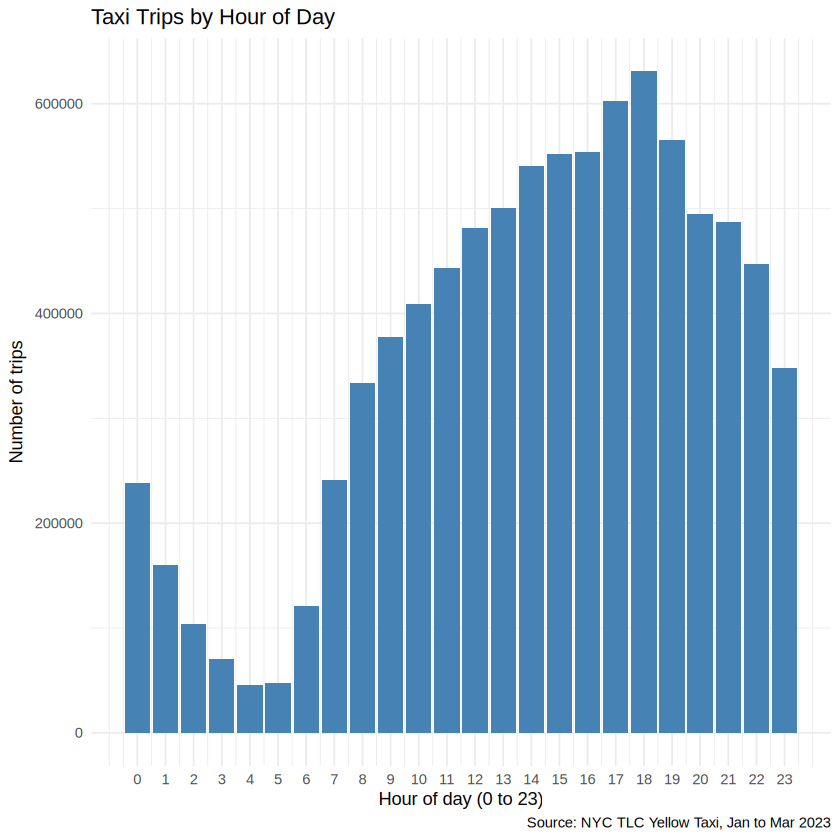

In [22]:
ggplot(hourly, aes(x = hour, y = trips)) +
  geom_col(fill = 'steelblue') +
  scale_x_continuous(breaks = 0:23) +
  labs(title = 'Taxi Trips by Hour of Day',
       x = 'Hour of day (0 to 23)',
       y = 'Number of trips',
       caption = 'Source: NYC TLC Yellow Taxi, Jan to Mar 2023') +
  theme_minimal()

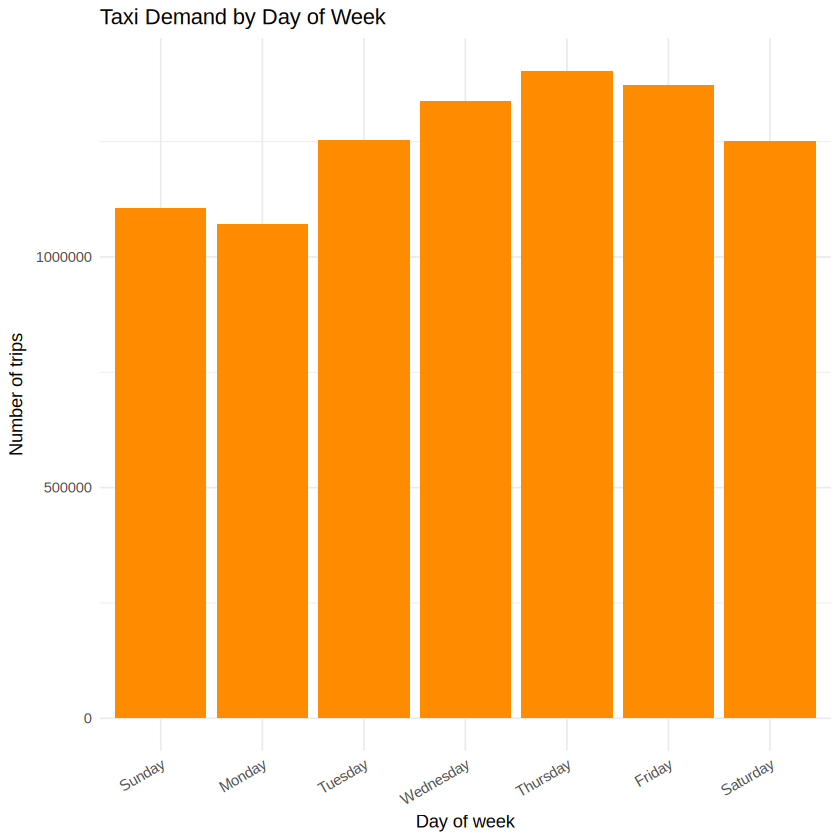

In [23]:
ggplot(dow, aes(x = wday, y = trips)) +
  geom_col(fill = 'darkorange') +
  labs(title = 'Taxi Demand by Day of Week',
       x = 'Day of week',
       y = 'Number of trips') +
  theme_minimal() +
  theme(axis.text.x = element_text(angle = 30, hjust = 1))

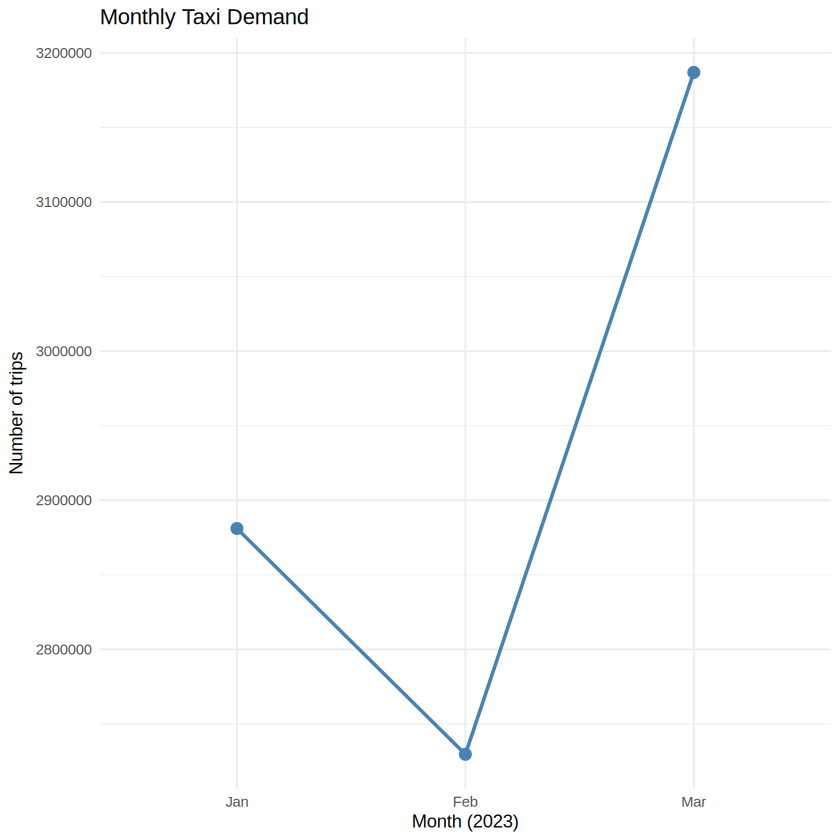

In [24]:
ggplot(monthly, aes(x = month, y = trips, group = 1)) +
  geom_line(colour = 'steelblue', linewidth = 1) +
  geom_point(size = 3, colour = 'steelblue') +
  labs(title = 'Monthly Taxi Demand',
       x = 'Month (2023)',
       y = 'Number of trips') +
  theme_minimal()

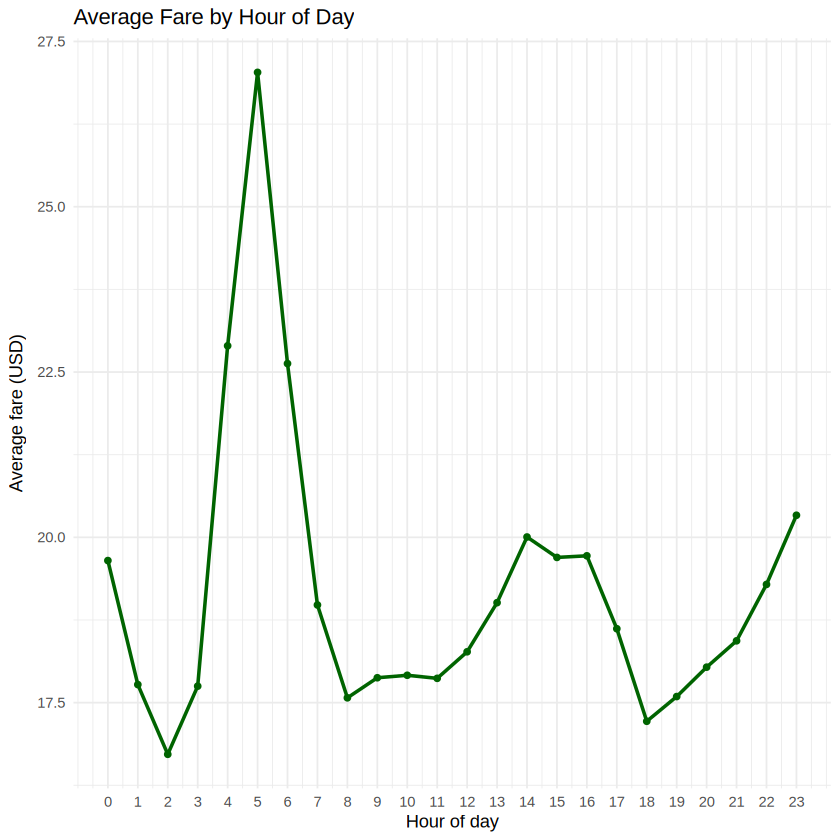

In [25]:
ggplot(hourly, aes(x = hour, y = avg_fare)) +
  geom_line(colour = 'darkgreen', linewidth = 1) +
  geom_point(colour = 'darkgreen') +
  scale_x_continuous(breaks = 0:23) +
  labs(title = 'Average Fare by Hour of Day',
       x = 'Hour of day',
       y = 'Average fare (USD)') +
  theme_minimal()

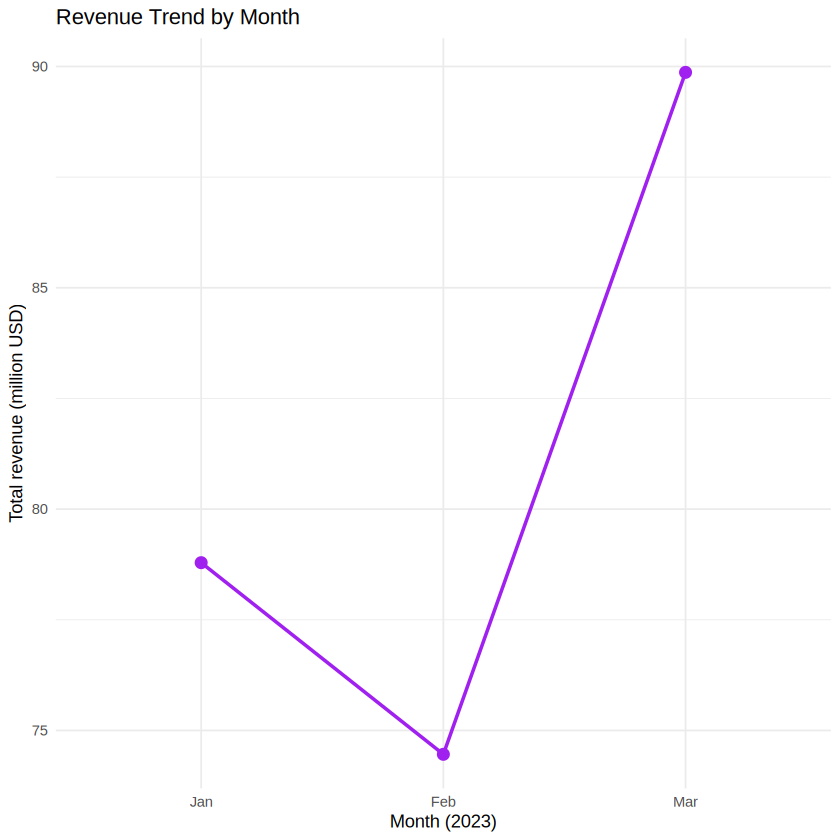

In [26]:
ggplot(monthly, aes(x = month, y = revenue / 1e6, group = 1)) +
  geom_line(colour = 'purple', linewidth = 1) +
  geom_point(size = 3, colour = 'purple') +
  labs(title = 'Revenue Trend by Month',
       x = 'Month (2023)',
       y = 'Total revenue (million USD)') +
  theme_minimal()

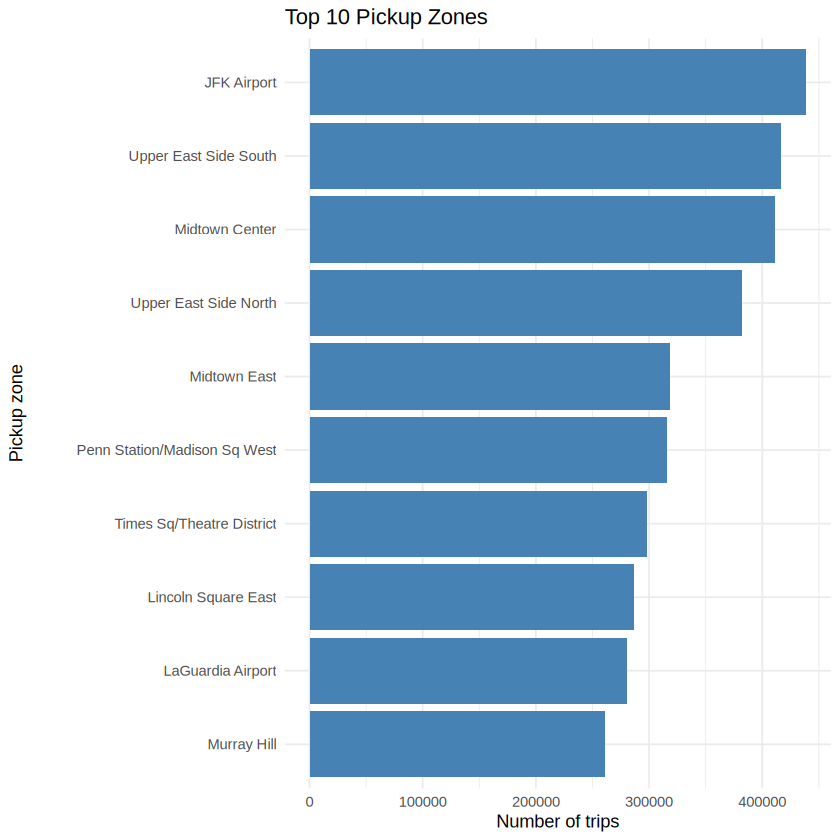

In [27]:
ggplot(top_pickup, aes(x = reorder(PU_Zone, N), y = N)) +
  geom_col(fill = 'steelblue') +
  coord_flip() +
  labs(title = 'Top 10 Pickup Zones',
       x = 'Pickup zone',
       y = 'Number of trips') +
  theme_minimal()

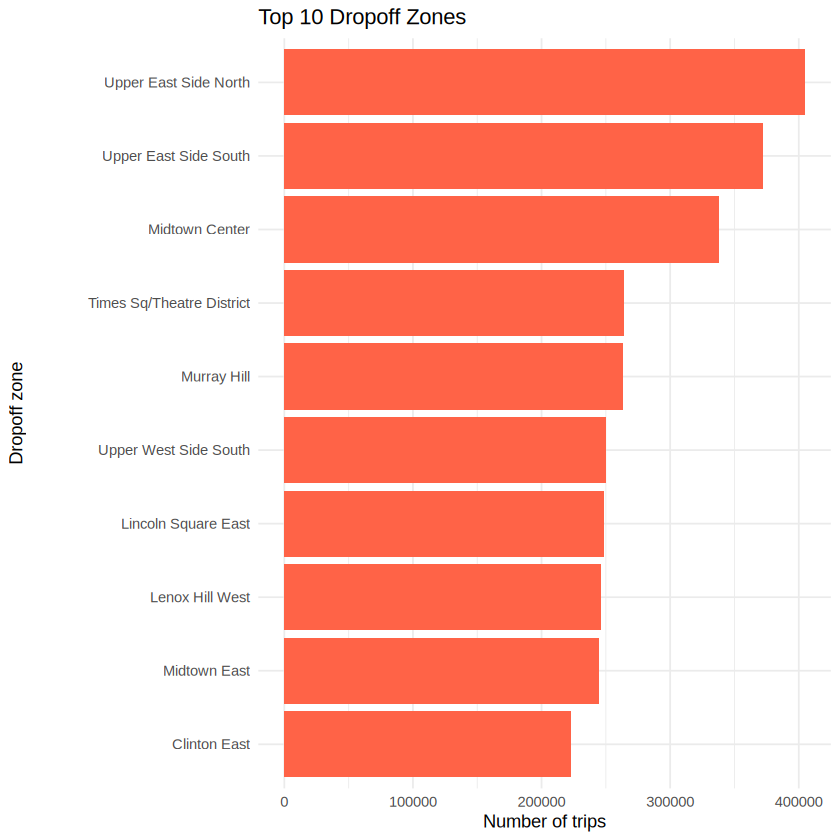

In [28]:
ggplot(top_dropoff, aes(x = reorder(DO_Zone, N), y = N)) +
  geom_col(fill = 'tomato') +
  coord_flip() +
  labs(title = 'Top 10 Dropoff Zones',
       x = 'Dropoff zone',
       y = 'Number of trips') +
  theme_minimal()

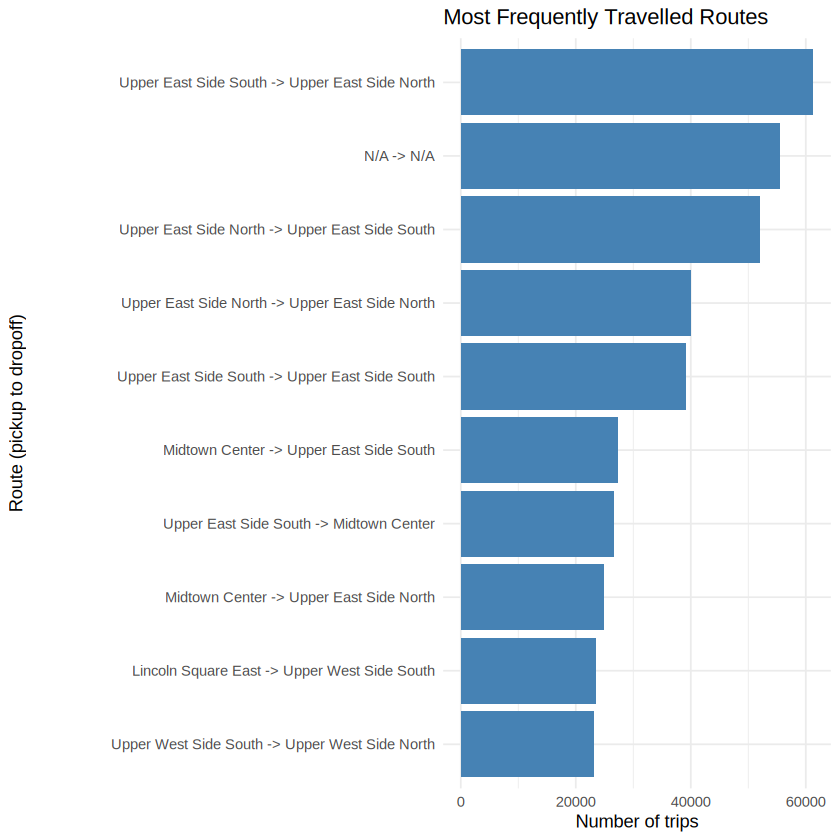

In [29]:
route_label_freq <- top_routes_freq[, paste(PU_Zone, '->', DO_Zone)]
ggplot(top_routes_freq, aes(x = reorder(route_label_freq, trips), y = trips)) +
  geom_col(fill = 'steelblue') +
  coord_flip() +
  labs(title = 'Most Frequently Travelled Routes',
       x = 'Route (pickup to dropoff)',
       y = 'Number of trips') +
  theme_minimal()

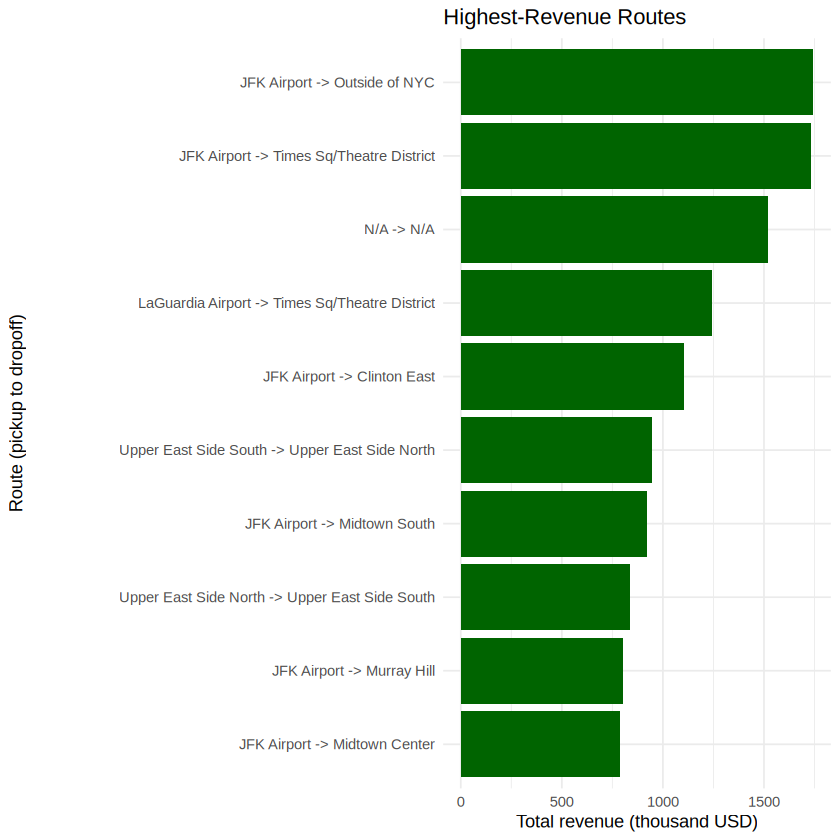

In [30]:
route_label_rev <- top_routes_rev[, paste(PU_Zone, '->', DO_Zone)]
ggplot(top_routes_rev, aes(x = reorder(route_label_rev, revenue), y = revenue / 1e3)) +
  geom_col(fill = 'darkgreen') +
  coord_flip() +
  labs(title = 'Highest-Revenue Routes',
       x = 'Route (pickup to dropoff)',
       y = 'Total revenue (thousand USD)') +
  theme_minimal()

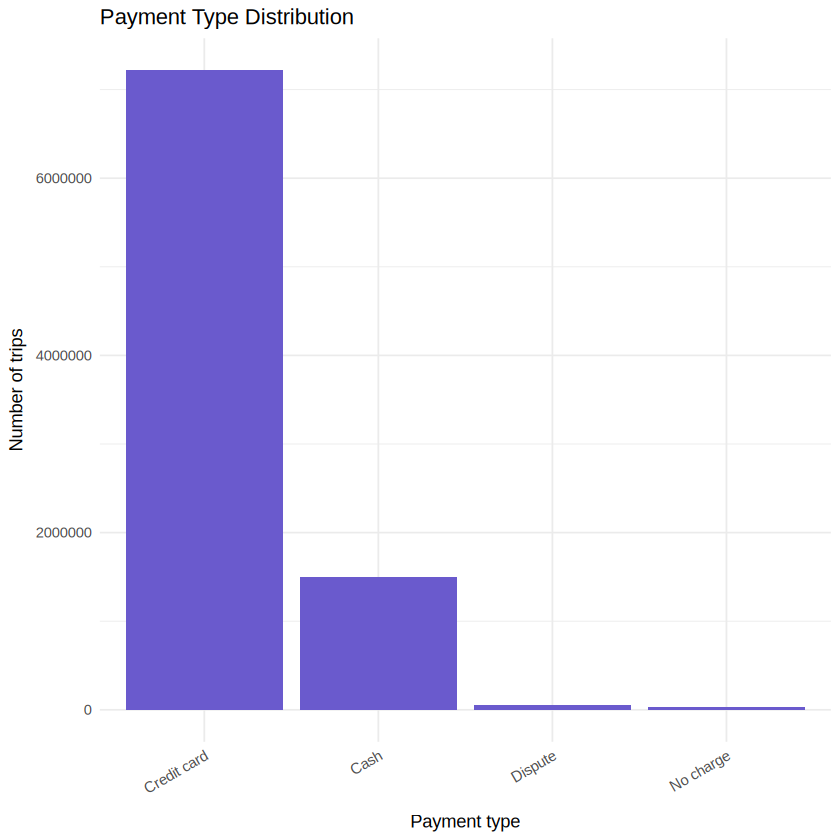

In [31]:
ggplot(payment_overall, aes(x = reorder(payment, -trips), y = trips)) +
  geom_col(fill = 'slateblue') +
  labs(title = 'Payment Type Distribution',
       x = 'Payment type',
       y = 'Number of trips') +
  theme_minimal() +
  theme(axis.text.x = element_text(angle = 30, hjust = 1))

`geom_smooth()` using formula = 'y ~ x'


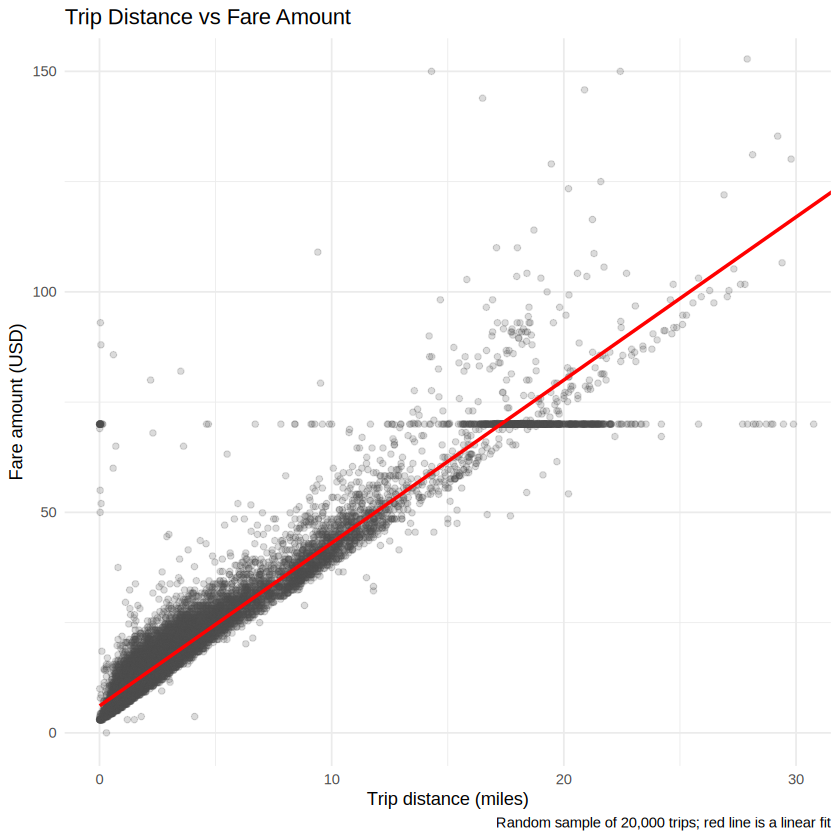

In [32]:
set.seed(7)
ggplot(trips[sample(.N, 20000)], aes(x = trip_distance, y = fare_amount)) +
  geom_point(alpha = 0.2, colour = 'grey30') +
  geom_smooth(method = 'lm', colour = 'red', se = FALSE) +
  coord_cartesian(xlim = c(0, 30), ylim = c(0, 150)) +
  labs(title = 'Trip Distance vs Fare Amount',
       x = 'Trip distance (miles)',
       y = 'Fare amount (USD)',
       caption = 'Random sample of 20,000 trips; red line is a linear fit') +
  theme_minimal()

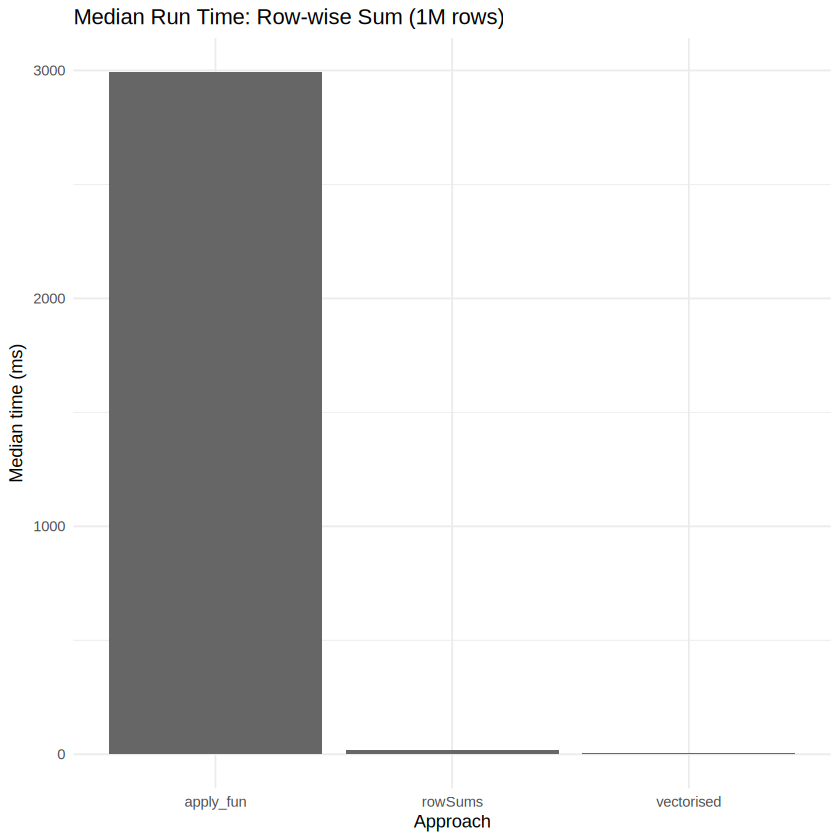

In [33]:
ggplot(bench_table[bench_table$task == 'Row-wise sum (1M rows)', ], aes(x = approach, y = median_ms)) +
  geom_col(fill = 'grey40') +
  labs(title = 'Median Run Time: Row-wise Sum (1M rows)',
       x = 'Approach',
       y = 'Median time (ms)') +
  theme_minimal()

## 9. Observations

Use the outputs above to fill in the points below with your own numbers. Do not copy values from this template, because they will differ from run to run.

1. **Demand by hour:** Identify the peak hour and the quietest hour from the hourly table. Explain the pattern using commuting, nightlife and late-night demand.
2. **Day of week:** Compare weekdays with weekends in the day-of-week table and chart.
3. **Monthly variation:** Describe how trips and revenue change from January to March. Mention any seasonal reasons you can think of.
4. **Fare and distance:** Use the correlation and the slope from the linear model to explain how much each extra mile adds to the fare. Mention outliers and the spread in the scatter plot.
5. **Routes:** Compare the most frequent routes with the highest-revenue routes. A route can be popular without being profitable, and the reverse is also true.
6. **Payment:** Compare credit card and cash shares, and the tip percentages. Explain why card payments are more likely to record tips.
7. **Unusual patterns:** Discuss the night-time share, the long-trip share and the zero-tip share, and suggest possible causes such as data entry issues or airport trips.

## 10. Critical Analysis and Recommendation (Task 7)

Answer each question using your own benchmark numbers from Sections 5 to 7.

1. **Best execution performance:** Which approach had the lowest median time in each benchmark group? Is the ranking the same for all groups?
2. **How data.table helps:** Explain the role of keys, reference semantics (`:=`) and grouped operations written in C. Relate this to the aggregation timings.
3. **When functional programming is preferable:** Discuss readability, flexibility for custom per-group logic (such as the bootstrap), and the cost of looping in R. Note where `apply()` was slower than `rowSums()`.
4. **When vectorized operations are better:** Use the row-wise results to explain why compiled vectorized code wins for simple arithmetic.
5. **Gain from parallel computing:** Report the speedup and efficiency from Section 6.3.
6. **Does parallel always help?** Consider the number of partitions, the cores available on Colab, worker start-up cost and data transfer to workers. Relate these to your measured speedup.
7. **Trade-offs:** Compare speed, memory (from Section 7.1), readability and scalability for each approach.
8. **Recommendation:** For a large-scale analytical application, recommend the approach or combination that the results support. A typical answer is data.table for data manipulation, vectorized code for simple arithmetic, and parallel workers only for independent, heavy per-partition tasks on a machine with enough cores.

## 11. Conclusion

This notebook processed about 9 million NYC yellow taxi trips with a reproducible R pipeline. data.table handled cleaning, joins and aggregation. Functional, vectorized and data.table versions of the same operations were compared with microbenchmark. Month-wise partitions were processed sequentially and in parallel with foreach and doParallel, and the speedup was reported. The findings on demand, fares, routes, revenue and payments are in Sections 4 and 8, and the critical evaluation is in Section 10.

**Submission checklist:** Run all cells, export the notebook to PDF (File → Print → Save as PDF), and push the `.ipynb` file to your Git repository with a README that lists the steps needed to reproduce the results.